---
# ***OBSCURA 🔭 Site-Aware Satellite Prediction***

---

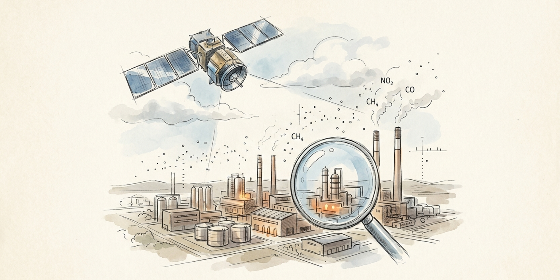
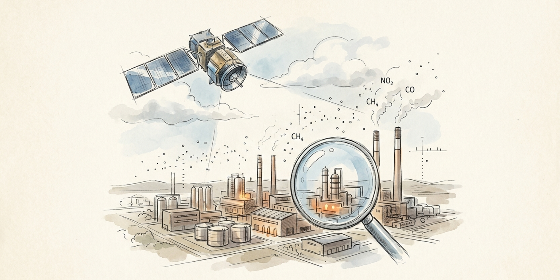

----
# ***About The Team***
---


We are a team of four memebers who worked together on the OBSCURA satellite prediction competition. We shared ideas, ran experiments and reviewed each other's results. This notebook describes our approach and what we learned along the way.

### *Team: Members:*
### 

| Name | Contact |
| --- | --- |
| Maria Nadeem | [Kaggle](https://www.kaggle.com/mnkaggler), [LinkedIn](https://www.linkedin.com/in/maria-nadeem-4994122aa/), [Email](mailto:marianadeem755@gmail.com) | 
| Mehak Iftikhar | [Kaggle](https://www.kaggle.com/mehakiftikhar)  [LinkedIn](https://www.linkedin.com/in/mehak-iftikhar),[Email](mailto:mehakkhan301007@gmail.com)|
| Maria Aqdas | [Kaggle](https://www.kaggle.com/mariaaqdas) [LinkedIn](https://www.linkedin.com/in/maria-aqdas-ds/), [Email](mailto:mariaaqdas786@gamil.com) |
| Anila Bukhari | [Kaggle](https://www.kaggle.com/anilabukhari) [LinkedIn](https://www.linkedin.com/in/anila-bukhari-b98a90388/), [Email](mailto:anilabukhari02@gamil.com) |

----
## ***Competition objective***
---

OBSCURA is a satellite-data prediction competition. For every sample we get one small satellite image (a *chip*) and 29 table columns (weather, terrain, month). From these we must predict **five numbers (targets)**:

| Target | What it measures |
| --- | --- |
| `t_ch4` | Methane |
| `t_no2` | Nitrogen dioxide |
| `t_co` | Carbon monoxide |
| `t_aai` | Aerosol index |
| `t_firms` | Fire score |

* **Data:** 3218 training rows from 81 sites, and 1221 test rows from **new sites** that the model has never seen.
* **Score:** MCRMSE, the mean of the five RMSE values (lower is better). If a target value is missing in the training file, it is skipped.
* **Why it is hard:** there are only 81 sites, so a flexible model can memorise a site instead of learning the real signal. Also, `t_ch4` and `t_co` have almost no learnable signal in the images.

---

## ***Data overview (EDA)***
---

**What the data looks like.**
* **Training:** 3218 rows from 81 sites, which is about 40 rows per site on average.
* **Test:** 1221 rows from new sites that do not appear in training.
* **Inputs per row:** one 14-layer satellite chip (12 light bands, a scene-classification layer and a cloud-probability layer) and 29 table columns (weather, terrain, month).
* **Targets:** five values per row: `t_ch4`, `t_no2`, `t_co`, `t_aai` and `t_firms`.

**Missing target values.** A blank target means "not measured" (for example because of cloud or quality filters). Blanks are skipped when the score is computed, but every target must still be predicted for every test row. According to the competition host, methane is blank most often, while the aerosol index and the fire score are almost never blank.

**Targets are on a similar scale.** The targets are standardised, and a model that predicts 0 for everything gets an error of about 1.0 on each target. This is why 1.0 is the "no skill" level in this notebook, and why our final model's 0.8483 is a real improvement over 0.9971.

**Rows of one site look alike.** About 40 rows share the same site, and rows from the same site have similar weather, terrain and image brightness. A model can therefore learn the site instead of the real signal. This is the main reason we keep whole sites together when we validate (Section 3).

**Some targets are almost unpredictable.** `t_ch4` and `t_co` showed almost no learnable signal in our experiments. Our honest validation RMSE for them is 0.9988 and 0.9869, close to the no-skill level of about 1.0. In one of our checks, the only pair of targets that was clearly linked within sites was `t_no2` and `t_co`.

**The evaluation metric**
The metric is MCRMSE, the mean of the five per-target RMSE values, lower is better. Targets are scaled so that always predicting 0 gives an RMSE of about 1.0 on every target. That makes 0 the natural, safe baseline: a prediction is only useful where it beats the zero guess on unseen sites.

**What we took from this.**
1. Validate on **whole sites**, not on random rows.
2. Use **small, simple models**, because there are only 81 sites.
3. **Shrink** the predictions of hard targets towards zero.
4. Build **separate features for each target**, because the targets behave differently.
---
## ***Our goal and approach***
---

**Our goal** is a model that works on **new, unseen sites**, not only one that gets a low validation or leaderboard score.

**Our approach, in simple steps:**

1. **Turn each chip into numbers.** We compute simple statistics from clear pixels, for example band averages, brightest infrared pixels (hot pixels) and urban-texture measures.
2. **Give each target its own feature table.** We added only the feature groups that helped that target in validation.
3. **Use small, simple models.** Histogram Gradient Boosting, Ridge, CatBoost and a two-stage "high or low" model for fires, averaged for each target.
4. **Shrink the predictions.** Each target's prediction is multiplied by a factor between 0 and 1, so hard targets stay close to zero.
5. **Test honestly.** We keep whole sites together in cross-validation, and score on sites the model has not seen.
6. **Judge every change by a rule written before the run.** The public leaderboard is only an independent check.

**Result:** the  model (V02) scores **1.01690** on the public leaderboard and **0.8483** on our honest validation, against 0.9971 for predicting all zeros. We use no pretrained models and no outside data.

----
## ***1. Setting & Imports***
---

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import ndimage
from scipy.ndimage import uniform_filter
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer
from threadpoolctl import threadpool_limits
from catboost import CatBoostRegressor         

warnings.filterwarnings("ignore")

os.environ["PYTHONWARNINGS"] = "ignore"

TARGETS    = ["t_ch4", "t_no2", "t_co", "t_aai", "t_firms"]
BAND_NAMES = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
J          = {t: i for i, t in enumerate(TARGETS)}


RECOMPUTE_FACTORS = False        
                                
FIXED_FACTORS = {"t_ch4": 0.438, "t_no2": 0.944, "t_co": 0.481, "t_aai": 1.000, "t_firms": 1.000}
FAST = os.environ.get("OBSCURA_FAST") == "1"    

# site-wise partitions
FACTOR_SEEDS = [1430, 1431] if FAST else [1430, 1431, 1432, 1433, 1434, 1435, 1436, 1437]  
GRID         = np.linspace(0, 1, 21)             
N_WORKERS    = max(1, min(4, os.cpu_count() or 1))

----
##  ***2. Find the data***
The notebook looks for `train.csv`, `test.csv`, `sample_submission.csv` and the `images/` folder under `/kaggle/input`.

---

In [2]:
def find_root():
    """Find the folder that holds train.csv, test.csv, sample_submission.csv and images/ (no assumptions)."""
    cands = ["/kaggle/input/competitions/obscura", "/kaggle/input/obscura"]
    for p in cands:
        if os.path.exists(os.path.join(p, "train.csv")):
            return p
    hits = []
    for dirpath, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files:
            hits.append(dirpath)
    for h in hits:
        if os.path.isdir(os.path.join(h, "images")):
            return h
    if hits:
        return hits[0]
    raise FileNotFoundError("train.csv/test.csv not found under /kaggle/input. Add the OBSCURA competition data "
                            "to this notebook (Add Input) and run again.")


def find_out_dir():
    d = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("obscura_output")
    os.makedirs(d, exist_ok=True)
    return d


def cached_table(path, ids, make_rows, expected_cols, label):
    """Reading the chips takes a while, so every feature table is saved once and re-used on later runs."""
    if os.path.exists(path):
        tab = pd.read_csv(path, dtype={"sample_id": str})
        if len(tab) == len(ids) and set(tab["sample_id"]) == set(ids) and tab.shape[1] == expected_cols:
            print(f"Using cached {label}")
            return tab.set_index("sample_id")
    t0 = time.time()
    tab = pd.DataFrame(make_rows())
    tab.to_csv(path, index=False)
    print(f"Computed {label} in {(time.time() - t0) / 60:.1f} min")
    return tab.set_index("sample_id")


ROOT, OUT_DIR = find_root(), find_out_dir()
train = pd.read_csv(f"{ROOT}/train.csv", dtype={"sample_id": str, "site_key": str})
test  = pd.read_csv(f"{ROOT}/test.csv",  dtype={"sample_id": str})
sub   = pd.read_csv(f"{ROOT}/sample_submission.csv", dtype={"sample_id": str})
 # the 29 tabular columns
feature_cols = [c for c in test.columns if c != "sample_id"]           
assert len(feature_cols) == 29 and sub["sample_id"].tolist() == test["sample_id"].tolist()

Y      = train[TARGETS].to_numpy(float)
# used ONLY to keep whole sites together in cross-validation
groups = train["site_key"].to_numpy()            
ids    = list(train["sample_id"]) + list(test["sample_id"])
print("data folder:", ROOT, "| train", train.shape, "| test", test.shape, "| FAST mode:", FAST)

data folder: /kaggle/input/competitions/obscura | train (3218, 36) | test (1221, 30) | FAST mode: False


----
## ***3. Turn each satellite chip into numbers (feature extraction)***
Every chip is a 14-layer image (12 Sentinel-2 bands + scene classification + cloud probability). We only use **clear, valid pixels** and compute simple statistics. Each block below is one *feature family*:

---
* **v1 / v2** – band means, spreads, percentiles, band ratios, vegetation / water indices, haze-style ratios, texture.
* **v3 / v4 / v7 / v16 / v17 / v23** – *hot-pixel* descriptors (brightest SWIR pixels, small bright clusters, local contrast, smoothed versions). These matter most for fires (`t_firms`) and gas plumes.
* **v19** – urban-texture descriptors (edges, local standard deviation, built-up index) used for `t_no2`.

The functions are run once per chip in parallel and the result is cached to CSV.

---

### ***Feature families at a glance***

 Each *family* is a group of features computed in the same way. 

| Family | What it measures (simple words) | Used for |
| --- | --- | --- |
| **v1** | Basic statistics per image band: mean, spread, percentiles | All targets |
| **v2** | Band ratios (for example B2/B4, B11/B8A), brightness percentiles, simple texture | All targets |
| **v3** | The brightest infrared (B11, B12) pixels and the biggest hot cluster | All targets (base table) |
| **v4** | More hot-pixel descriptors: number and size of bright clusters | `t_firms` |
| **v7** | Share of pixels above brightness thresholds, hot clusters, local contrast | `t_firms` |
| **v16** | Brightness-threshold shares and hot-pixel groups | `t_aai`, `t_firms` |
| **v17** | The same hot-pixel idea on a smoothed image | `t_firms` |
| **v23** | Finer brightest-pixel ranks (for example 2nd, 4th, 7th brightest) | `t_firms` |
| **v19** | Urban texture: edges, local spread, built-up index | `t_no2` |

**Why these groups:** the hot-pixel families (v3, v4, v7, v16, v17, v23) were designed for fires (`t_firms`) and plumes, because a fire is a few very bright infrared pixels (**hypothesis**). The urban-texture family (v19) was designed for `t_no2`, because traffic and industry create built-up texture (**hypothesis**). Which family each target actually uses is decided by validation (Section 4).

---

> ### _***3.1 Chip reading helpers***_ 

In [3]:
## chip reading helpers
def read_chip(path):
    try:
        import rasterio
    except ImportError:
        import tifffile
        arr = tifffile.imread(path)
        if arr.ndim == 3 and arr.shape[0] != 14 and arr.shape[-1] == 14:
            arr = np.moveaxis(arr, -1, 0)
        return arr
    with rasterio.open(path) as src:
        return src.read()


def _nd(a, c):
    return (a - c) / (a + c + 1e-6)


def chip_mask(arr):
    """Clear (CLDPRB < 40) and valid (no zero in B1-B12) pixels, with the same fallbacks as v1."""
    valid = ~(arr[:12] == 0).any(axis=0)
    clear = arr[13] < 40
    mask = valid & clear
    if mask.sum() < 500:
        mask = valid
        if mask.sum() < 500:
            mask = np.ones_like(valid)
    return mask, valid

> ### _***3.2 v1 (83 features) and v2 (20 features)***_ 

In [4]:
## v1 (83 features) and v2 (20 features)
V2_NAMES = ([f"v2_{r}_{q}" for r in ["B2B4", "B3B4", "B1B2", "B11B8A", "B9B8A"] for q in ["p10", "p50", "p90"]]
            + ["v2_vis_p10", "v2_vis_p50", "v2_vis_p90", "v2_tex_B8", "v2_tex_B4"])

def chip_features(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    scl, cld = arr[12], arr[13]
    valid = ~(arr[:12] == 0).any(axis=0)
    clear = cld < 40
    mask, used = valid & clear, "clear_valid"
    if mask.sum() < 500:
        mask, used = valid, "valid_only"
        if mask.sum() < 500:
            mask, used = np.ones_like(valid), "all"

    f = {"sample_id": sid, "img_mask_used": used, "img_frac_mask": float(mask.mean()),
         "img_frac_valid": float(valid.mean()), "img_frac_cloud40": float((cld >= 40).mean()),
         "img_cldprb_mean": float(cld.mean())}
    for c in range(12):
        f[f"img_scl{c}"] = float((scl == c).mean())

    for k, n in enumerate(BAND_NAMES):
        x = b[k][mask]
        p10, p90 = np.percentile(x, [10, 90])
        f[f"img_{n}_mean"], f[f"img_{n}_std"] = float(x.mean()), float(x.std())
        f[f"img_{n}_p10"], f[f"img_{n}_p90"] = float(p10), float(p90)

    B3, B4, B8, B11, B12 = b[2], b[3], b[7], b[10], b[11]
    idx = {"ndvi": _nd(B8, B4), "ndwi": _nd(B3, B8), "nbr": _nd(B8, B12),
           "swirratio": B11 / (B12 + 1e-6)}
    for n, v in idx.items():
        x = v[mask]
        f[f"img_{n}_mean"], f[f"img_{n}_std"] = float(x.mean()), float(x.std())
        f[f"img_{n}_p90"] = float(np.percentile(x, 90))

    f["img_B11_p99"] = float(np.percentile(B11[mask], 99))
    f["img_B12_p99"] = float(np.percentile(B12[mask], 99))
    f["img_B12_gt025"] = float((B12[mask] > 0.25).mean())
    f["img_B12_gt040"] = float((B12[mask] > 0.40).mean())

    h, w = mask.shape
    r0, r1, c0, c1 = int(0.375 * h), int(0.625 * h), int(0.375 * w), int(0.625 * w)   # 144:240 for 384
    cm = mask[r0:r1, c0:c1]
    for n, v in [("B11", B11), ("B12", B12), ("ndvi", idx["ndvi"])]:
        f[f"img_{n}_center_minus_all"] = (float(v[r0:r1, c0:c1][cm].mean() - v[mask].mean())
                                          if cm.sum() > 100 else np.nan)
    return f


# chip features v2 (20 numbers)
def chip_features_v2(sid, img_dir):
    """Pixel-level haze/aerosol-style ratio percentiles, visible brightness percentiles, spatial texture."""
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    eps = 1e-6
    f = {"sample_id": sid}
    ratios = {"B2B4": b[1] / (b[3] + eps), "B3B4": b[2] / (b[3] + eps), "B1B2": b[0] / (b[1] + eps),
              "B11B8A": b[10] / (b[8] + eps), "B9B8A": b[9] / (b[8] + eps)}
    for n, v in ratios.items():
        p = np.percentile(v[mask], [10, 50, 90])
        for q, val in zip(["p10", "p50", "p90"], p):
            f[f"v2_{n}_{q}"] = float(val)
    vis = (b[1] + b[2] + b[3]) / 3
    for q, val in zip(["p10", "p50", "p90"], np.percentile(vis[mask], [10, 50, 90])):
        f[f"v2_vis_{q}"] = float(val)
    mx = mask[:, 1:] & mask[:, :-1]
    my = mask[1:, :] & mask[:-1, :]
    for n, k in [("B8", 7), ("B4", 3)]:
        band = b[k]
        gx = np.abs(np.diff(band, axis=1))[mx]
        gy = np.abs(np.diff(band, axis=0))[my]
        g = np.concatenate([gx, gy])
        f[f"v2_tex_{n}"] = float(g.mean() / (band[mask].mean() + eps)) if g.size else np.nan
    return f

> ### _***3.3 v3: brightest SWIR pixels and the biggest hot cluster***_ 

In [5]:
## v3: brightest SWIR pixels and the biggest hot cluster
V3B = ["B11", "B12"]
V3_NAMES = ([f"v3_{b}_{k}" for b in V3B for k in ["top1", "top10", "top100", "z3", "z5"]]
            + ["v3_fi_top10", "v3_B12mB8A_top10", "v3_ncomp", "v3_maxcomp_size", "v3_maxcomp_mean", "v3_B12_top100_over_med"])


def _topmean(x, k):
    k = min(k, x.size)
    return float(np.partition(x, -k)[-k:].mean())


def chip_features_v3(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    eps = 1e-6
    f = {"sample_id": sid}
    B11, B12, B8A = b[10], b[11], b[8]
    for n, band in [("B11", B11), ("B12", B12)]:
        x = band[mask]
        z = (x - x.mean()) / (x.std() + eps)
        f[f"v3_{n}_top1"] = float(x.max())
        f[f"v3_{n}_top10"] = _topmean(x, 10)
        f[f"v3_{n}_top100"] = _topmean(x, 100)
        f[f"v3_{n}_z3"] = float((z > 3).mean())
        f[f"v3_{n}_z5"] = float((z > 5).mean())
    fi = ((B12 - B11) / (B12 + B11 + eps))[mask]
    f["v3_fi_top10"] = _topmean(fi, 10)
    f["v3_B12mB8A_top10"] = _topmean((B12 - B8A)[mask], 10)
    x = B12[mask]
    thr = x.mean() + 3 * x.std()
    hot = (B12 > thr) & mask
    lab, n = ndimage.label(hot)
    if n > 0:
        sizes = ndimage.sum(hot, lab, index=np.arange(1, n + 1))
        k = int(np.argmax(sizes)) + 1
        f["v3_ncomp"], f["v3_maxcomp_size"] = float(n), float(sizes[k - 1])
        f["v3_maxcomp_mean"] = float(B12[lab == k].mean())
    else:
        f["v3_ncomp"], f["v3_maxcomp_size"], f["v3_maxcomp_mean"] = 0.0, 0.0, float(thr)
    f["v3_B12_top100_over_med"] = _topmean(x, 100) / (float(np.median(x)) + eps)
    return f

> ### _***3.4 v4: more hot-pixel descriptors***_ 

In [6]:
#v4: more hot-pixel descriptors
H1N = [f"v4_c{z}_{k}" for z in (2, 4) for k in ("ncomp", "maxsize", "maxmean")]
H2N = ["v4_hot_B11", "v4_hot_B8A", "v4_hot_B4", "v4_hot_B2", "v4_hot_B12_over_B11", "v4_hot_B11_over_B8A", "v4_hot_B12_over_B8A"]
H3N = ["v4_hot_centre_offset", "v4_hot_spread", "v4_hot_central_share", "v4_lc_B12_top10", "v4_lc_B12_top100", "v4_lc_B11_top10"]
V4_NAMES = H1N + H2N + H3N


def chip_features_v4(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    eps = 1e-6
    B2, B4, B8A, B11, B12 = b[1], b[3], b[8], b[10], b[11]
    f = {"sample_id": sid}
    x = B12[mask]
    mu, sd = float(x.mean()), float(x.std())
    for z in (2, 4):
        hot = (B12 > mu + z * sd) & mask
        lab, n = ndimage.label(hot)
        if n > 0:
            sizes = ndimage.sum(hot, lab, index=np.arange(1, n + 1))
            k = int(np.argmax(sizes)) + 1
            f[f"v4_c{z}_ncomp"], f[f"v4_c{z}_maxsize"], f[f"v4_c{z}_maxmean"] = float(n), float(sizes[k - 1]), float(B12[lab == k].mean())
        else:
            f[f"v4_c{z}_ncomp"], f[f"v4_c{z}_maxsize"], f[f"v4_c{z}_maxmean"] = 0.0, 0.0, mu + z * sd
    vals = np.where(mask, B12, -np.inf).ravel()
    kk = int(min(100, mask.sum()))
    idx = np.argpartition(vals, -kk)[-kk:]
    m = {n: float(band.ravel()[idx].mean()) for n, band in [("B11", B11), ("B8A", B8A), ("B4", B4), ("B2", B2), ("B12", B12)]}
    for n in ("B11", "B8A", "B4", "B2"):
        f[f"v4_hot_{n}"] = m[n]
    f["v4_hot_B12_over_B11"] = m["B12"] / (m["B11"] + eps)
    f["v4_hot_B11_over_B8A"] = m["B11"] / (m["B8A"] + eps)
    f["v4_hot_B12_over_B8A"] = m["B12"] / (m["B8A"] + eps)
    hot3 = (B12 > mu + 3 * sd) & mask
    h, w = mask.shape
    if hot3.sum() >= 2:
        ys, xs = np.nonzero(hot3)
        f["v4_hot_centre_offset"] = float(np.sqrt(((ys.mean() - h / 2) / h) ** 2 + ((xs.mean() - w / 2) / w) ** 2))
        f["v4_hot_spread"] = float(np.sqrt(ys.var() + xs.var()) / h)
        r0, r1, c0, c1 = int(0.375 * h), int(0.625 * h), int(0.375 * w), int(0.625 * w)
        f["v4_hot_central_share"] = float(hot3[r0:r1, c0:c1].sum() / hot3.sum())
    else:
        f["v4_hot_centre_offset"] = f["v4_hot_spread"] = f["v4_hot_central_share"] = 0.0    
    for n, band, k in [("B12", B12, 10), ("B12", B12, 100), ("B11", B11, 10)]:
        d = (band - ndimage.median_filter(band, size=7))[mask]
        f[f"v4_lc_{n}_top{k}"] = _topmean(d, k)
    return f

> ### _***3.5  v7: threshold shares, hot clusters, local contrast, NBR shares***_ 

In [7]:
# v7: threshold shares, hot clusters, local contrast, NBR shares
V7_NAMES = ["v7_B12_gt03", "v7_B12_gt04", "v7_B12_gt05", "v7_fa_share", "v7_fa_logn", "v7_fa_ncomp", "v7_fa_maxsize", "v7_fb_share",
            "v7_r128a_top10", "v7_lc15_B12_top10", "v7_lc31_B12_top10", "v7_lc15_B11_top10", "v7_nbr_low10", "v7_nbr_lt01", "v7_nbr_ltm01"]


def chip_features_v7(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    eps = 1e-6
    B8A, B11, B12 = b[8], b[10], b[11]
    f = {"sample_id": sid}
    nv = max(int(mask.sum()), 1)
    x12 = B12[mask]
    for t, nm in ((0.3, "03"), (0.4, "04"), (0.5, "05")):
        f[f"v7_B12_gt{nm}"] = float((x12 > t).sum() / nv)
    fa = (B12 / (B8A + eps) > 1.8) & ((B12 - B8A) > 0.17) & mask          # ratio + difference test (fixed thresholds)
    f["v7_fa_share"] = float(fa.sum() / nv)
    f["v7_fa_logn"] = float(np.log1p(fa.sum()))
    lab, n = ndimage.label(fa)
    f["v7_fa_ncomp"] = float(n)
    f["v7_fa_maxsize"] = float(ndimage.sum(fa, lab, index=np.arange(1, n + 1)).max()) if n > 0 else 0.0
    fb = (B12 > B11) & (B11 > B8A) & (B12 > 0.25) & mask
    f["v7_fb_share"] = float(fb.sum() / nv)
    f["v7_r128a_top10"] = _topmean((B12 / np.maximum(B8A, 0.02))[mask], 10)
    for nm, band, w in (("lc15_B12", B12, 15), ("lc31_B12", B12, 31), ("lc15_B11", B11, 15)):
        f[f"v7_{nm}_top10"] = _topmean((band - uniform_filter(band, w))[mask], 10)
    nbr = ((B8A - B12) / (B8A + B12 + eps))[mask]
    k = max(1, int(0.1 * nbr.size))
    f["v7_nbr_low10"] = float(np.partition(nbr, k - 1)[:k].mean())
    f["v7_nbr_lt01"] = float((nbr < 0.1).mean())
    f["v7_nbr_ltm01"] = float((nbr < -0.1).mean())
    return f

> ### _***3.6  v16: brightness thresholds + hot-pixel families***_ 

In [8]:
## v16: brightness thresholds + hot-pixel families
V16B_NAMES = (["v16_B12_gt%03d" % int(round(t_ * 100)) for t_ in (0.10, 0.15, 0.20, 0.30, 0.35)] + ["v16_B11_gt%03d" % int(round(t_ * 100)) for t_ in (0.15, 0.20, 0.25, 0.30, 0.40)]
              + ["v16_B2_gt%03d" % int(round(t_ * 100)) for t_ in (0.10, 0.15, 0.20)] + ["v16_B12_p25", "v16_B12_p50", "v16_B12_p75", "v16_B11_p50", "v16_bare_share", "v16_bare_B12_med"])
V16H_NAMES = (["v16_d12_8a_top%d" % k_ for k_ in (1, 3, 5, 25, 100)] + ["v16_d12_11_top1", "v16_d12_11_top10", "v16_d12_4_top10"]
              + ["v16_d12_8a_gt%03d" % int(round(t_ * 100)) for t_ in (0.05, 0.10, 0.15, 0.25)] + ["v16_d12_8a_n15_log", "v16_d12_8a_maxcomp15", "v16_d12_8a_at_top100_B12", "v16_d12_8a_p99", "v16_d12_8a_p90"])
V16_NAMES = V16B_NAMES + V16H_NAMES


def chip_features_v16(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    eps = 1e-6
    B2, B4, B8A, B11, B12 = b[1], b[3], b[8], b[10], b[11]
    f = {"sample_id": sid}
    f.update({k: np.nan for k in V16_NAMES})
    nv = int(mask.sum())
    if nv < 200:
        return f
    x12, x11, x2 = B12[mask], B11[mask], B2[mask]
    for t_ in (0.10, 0.15, 0.20, 0.30, 0.35):
        f["v16_B12_gt%03d" % int(round(t_ * 100))] = float((x12 > t_).mean())
    for t_ in (0.15, 0.20, 0.25, 0.30, 0.40):
        f["v16_B11_gt%03d" % int(round(t_ * 100))] = float((x11 > t_).mean())
    for t_ in (0.10, 0.15, 0.20):
        f["v16_B2_gt%03d" % int(round(t_ * 100))] = float((x2 > t_).mean())
    f["v16_B12_p25"], f["v16_B12_p50"], f["v16_B12_p75"] = [float(v_) for v_ in np.percentile(x12, [25, 50, 75])]
    f["v16_B11_p50"] = float(np.median(x11))
    ndvi = (B8A - B4) / (B8A + B4 + eps)
    bare = mask & (ndvi < 0.2) & (B12 > 0.2)
    f["v16_bare_share"] = float(bare.sum() / nv)
    if bare.sum() >= 30:
        f["v16_bare_B12_med"] = float(np.median(B12[bare]))
    d = (B12 - B8A)
    dm = d[mask]
    for k_ in (1, 3, 5, 25, 100):
        f["v16_d12_8a_top%d" % k_] = _topmean(dm, k_)
    f["v16_d12_11_top1"] = _topmean((B12 - B11)[mask], 1)
    f["v16_d12_11_top10"] = _topmean((B12 - B11)[mask], 10)
    f["v16_d12_4_top10"] = _topmean((B12 - B4)[mask], 10)
    for t_ in (0.05, 0.10, 0.15, 0.25):
        f["v16_d12_8a_gt%03d" % int(round(t_ * 100))] = float((dm > t_).mean())
    hot = (d > 0.15) & mask
    f["v16_d12_8a_n15_log"] = float(np.log1p(hot.sum()))
    if hot.any():
        lab, n_ = ndimage.label(hot)
        f["v16_d12_8a_maxcomp15"] = float(ndimage.sum(hot, lab, index=np.arange(1, n_ + 1)).max())
    else:
        f["v16_d12_8a_maxcomp15"] = 0.0
    top = np.argsort(x12)[-100:]
    f["v16_d12_8a_at_top100_B12"] = float(dm[top].mean())
    f["v16_d12_8a_p99"], f["v16_d12_8a_p90"] = float(np.percentile(dm, 99)), float(np.percentile(dm, 90))
    return f

> ### _***3.7  v17: smoothed hot-pixel features***_ 

In [9]:
## v17: smoothed hot-pixel features
V17_NAMES = ["v17_s3_top1", "v17_s3_top5", "v17_s3_top25", "v17_s5_top1", "v17_s5_top10", "v17_loc_top1", "v17_loc_top10", "v17_nbr_hot_log", "v17_b11s3_top5", "v17_core_B12"]


def chip_features_v17(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    f = {"sample_id": sid}
    f.update({k: np.nan for k in V17_NAMES})
    if int(mask.sum()) < 200:
        return f
    B8A, B11, B12 = b[8], b[10], b[11]
    d = B12 - B8A
    dd = np.where(mask, d, np.median(d[mask]))
    s3, s5 = ndimage.uniform_filter(dd, 3), ndimage.uniform_filter(dd, 5)
    loc = dd - ndimage.uniform_filter(dd, 31)
    f["v17_s3_top1"], f["v17_s3_top5"], f["v17_s3_top25"] = [_topmean(s3[mask], k_) for k_ in (1, 5, 25)]
    f["v17_s5_top1"], f["v17_s5_top10"] = [_topmean(s5[mask], k_) for k_ in (1, 10)]
    f["v17_loc_top1"], f["v17_loc_top10"] = [_topmean(loc[mask], k_) for k_ in (1, 10)]
    hotb = (dd > 0.10) & mask
    cnt = ndimage.uniform_filter(hotb.astype("float32"), 3) * 9
    f["v17_nbr_hot_log"] = float(np.log1p((hotb & (cnt >= 3)).sum()))
    d11 = np.where(mask, B11 - B8A, np.median((B11 - B8A)[mask]))
    f["v17_b11s3_top5"] = _topmean(ndimage.uniform_filter(d11, 3)[mask], 5)
    core = (s3 > 0.10) & mask
    if core.sum() >= 3:
        f["v17_core_B12"] = float(B12[core].mean())
    return f

> ### _***3.8  v19: urban-texture family***_ 

In [10]:
## v19: urban-texture family
V19_NAMES = (["v19_g%d_%s" % (sg, bn) for bn in ("B8", "B4", "B11") for sg in (1, 2, 4)] + ["v19_lstd9_B8", "v19_lstd27_B8", "v19_edge05_B8", "v19_edge10_B8",
             "v19_ndbi_mean", "v19_ndbi_std", "v19_ndbi_p90", "v19_ndbi_pos", "v19_scale_ratio_B8"])


def chip_features_v19(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    f = {"sample_id": sid}
    f.update({k: np.nan for k in V19_NAMES})
    if int(mask.sum()) < 200:
        return f
    eps = 1e-6
    bands = {"B4": b[3], "B8": b[7], "B11": b[10]}
    norm = {}
    for bn, x in bands.items():
        mu = float(x[mask].mean())
        xn = np.where(mask, x, mu) / (mu + eps)
        norm[bn] = xn
        for sg in (1, 2, 4):
            f["v19_g%d_%s" % (sg, bn)] = float(ndimage.gaussian_gradient_magnitude(xn, sg)[mask].mean())
    x8 = norm["B8"]
    for k_, w_ in (("lstd9_B8", 9), ("lstd27_B8", 27)):
        m1, m2 = ndimage.uniform_filter(x8, w_), ndimage.uniform_filter(x8 * x8, w_)
        f["v19_" + k_] = float(np.sqrt(np.maximum(m2 - m1 * m1, 0))[mask].mean())
    g1 = ndimage.gaussian_gradient_magnitude(x8, 1)[mask]
    f["v19_edge05_B8"], f["v19_edge10_B8"] = float((g1 > 0.05).mean()), float((g1 > 0.10).mean())
    ndbi = ((b[10] - b[7]) / (b[10] + b[7] + eps))[mask]
    f["v19_ndbi_mean"], f["v19_ndbi_std"], f["v19_ndbi_p90"], f["v19_ndbi_pos"] = float(ndbi.mean()), float(ndbi.std()), float(np.percentile(ndbi, 90)), float((ndbi > 0).mean())
    f["v19_scale_ratio_B8"] = float(ndimage.uniform_filter(x8, 9)[mask].std() / (x8[mask].std() + eps))
    return f

> ### _***3.9  v23: finer hot-pixel ranks***_ 

In [11]:
## v23: finer hot-pixel ranks
V23_NAMES = (["v23_d12_8a_top%d" % k_ for k_ in (2, 4, 7, 10, 15, 50, 200)] + ["v23_gap_1_5", "v23_gap_5_25", "v23_gap_25_100"]
             + ["v23_d12_8_top1", "v23_d12_8_top5", "v23_d12_8_top25"])


def chip_features_v23(sid, img_dir):
    arr = read_chip(f"{img_dir}/{sid}.tif")
    b = arr[:12].astype("float32") / 1e4
    mask, _ = chip_mask(arr)
    f = {"sample_id": sid}
    f.update({k: np.nan for k in V23_NAMES})
    if int(mask.sum()) < 200:
        return f
    dm = (b[11] - b[8])[mask]
    for k_ in (2, 4, 7, 10, 15, 50, 200):
        f["v23_d12_8a_top%d" % k_] = _topmean(dm, k_)
    t1, t5, t25, t100 = _topmean(dm, 1), _topmean(dm, 5), _topmean(dm, 25), _topmean(dm, 100)
    f["v23_gap_1_5"], f["v23_gap_5_25"], f["v23_gap_25_100"] = t1 - t5, t5 - t25, t25 - t100
    d8 = (b[11] - b[7])[mask]
    for k_ in (1, 5, 25):
        f["v23_d12_8_top%d" % k_] = _topmean(d8, k_)
    return f

----
### ***Run the extraction (cached)***
This step reads every satellite chip and saves the features to CSV files. 

----

In [12]:
def table_of(fname, fn, names, label):
    t = cached_table(os.path.join(OUT_DIR, fname), ids,
                     lambda: Parallel(n_jobs=N_WORKERS, verbose=0)(delayed(fn)(s, f"{ROOT}/images") for s in ids),
                     len(names) + 1, label)
    assert list(t.columns) == names, f"{label}: columns are not as expected"
    assert not np.isinf(t.to_numpy()).any()
    return t.loc[train["sample_id"]].to_numpy(float), t.loc[test["sample_id"]].to_numpy(float)

img = cached_table(os.path.join(OUT_DIR, "chip_features.csv"), ids,
                   lambda: Parallel(n_jobs=N_WORKERS, verbose=0)(delayed(chip_features)(s, f"{ROOT}/images") for s in ids), 85, "chip features v1")
img_cols = [c for c in img.columns if c != "img_mask_used"]
v2 = cached_table(os.path.join(OUT_DIR, "chip_features_v2.csv"), ids,
                  lambda: Parallel(n_jobs=N_WORKERS, verbose=0)(delayed(chip_features_v2)(s, f"{ROOT}/images") for s in ids), 21, "chip features v2")
assert len(img_cols) == 83 and list(v2.columns) == V2_NAMES

V3_tr,  V3_te  = table_of("chip_features_v3.csv",  chip_features_v3,  V3_NAMES,  "v3 (hot pixels)")
V4_tr,  V4_te  = table_of("chip_features_v4.csv",  chip_features_v4,  V4_NAMES,  "v4 (hot pixels)")
V7_tr,  V7_te  = table_of("chip_features_v7.csv",  chip_features_v7,  V7_NAMES,  "v7")
V16_tr, V16_te = table_of("chip_features_v16.csv", chip_features_v16, V16_NAMES, "v16")
V17_tr, V17_te = table_of("chip_features_v17.csv", chip_features_v17, V17_NAMES, "v17")
V19_tr, V19_te = table_of("chip_features_v19.csv", chip_features_v19, V19_NAMES, "v19 (urban texture)")
V23_tr, V23_te = table_of("chip_features_v23.csv", chip_features_v23, V23_NAMES, "v23")

Computed chip features v1 in 3.3 min
Computed chip features v2 in 2.1 min
Computed v3 (hot pixels) in 1.8 min
Computed v4 (hot pixels) in 10.0 min
Computed v7 in 2.0 min
Computed v16 in 1.9 min
Computed v17 in 1.6 min
Computed v19 (urban texture) in 4.1 min
Computed v23 in 1.3 min


----
## ***4. Build the feature matrix of each target***

----
**Base table** = the 29 tabular columns + v1 chip features + band ratios (`x_`), adjacent-band ratios (`a_`) + v2 + v3.
Two versions exist: one for the tree models (without `elevation` and `slope`) and one for Ridge (with them).

Then every target adds only what helped it in validation:

| Target | Matrix | What is added to the base table |
|---|---|---|
| `t_ch4` | `base` | nothing |
| `t_co` | `base` | nothing |
| `t_no2` | `P1` | v19 urban texture + **P1** = (1 / (wind + 1)) and wind-weighted texture features |
| `t_aai` | `A2m` | all v16 features + **A2** = z-scored products (solar radiation × surface features, temperature × bare-surface share) |
| `t_firms` | `D1m` | v4 + v7 + v16 hot-pixel + v17 + v23, and **D1** = all `img_`, `x_` and "other" columns *removed* (130 noisy columns) |

---

In [13]:
# base tables 
def build_derived(img):
    def ratio(a, b):
        return img[f"img_{a}_mean"] / (img[f"img_{b}_mean"] + 1e-6)
    new = pd.DataFrame({"x_B1_B2": ratio("B1", "B2"), "x_B2_B4": ratio("B2", "B4"), "x_B3_B4": ratio("B3", "B4"),
                        "x_B8A_B4": ratio("B8A", "B4"), "x_B9_B8A": ratio("B9", "B8A"),
                        "x_B11_B8A": ratio("B11", "B8A"), "x_B12_B11": ratio("B12", "B11")}, index=img.index)
    for b in ["B1", "B2", "B3", "B4", "B8", "B11", "B12"]:
        mu = img[f"img_{b}_mean"] + 1e-6
        new[f"x_cv_{b}"] = img[f"img_{b}_std"] / mu
        new[f"x_rng_{b}"] = (img[f"img_{b}_p90"] - img[f"img_{b}_p10"]) / mu
    return new

def build_adjacent(img):
    pairs = [("B2", "B3"), ("B4", "B5"), ("B5", "B6"), ("B6", "B7"), ("B7", "B8"), ("B8", "B8A"), ("B9", "B11")]
    return pd.DataFrame({f"a_{a}_{b}": img[f"img_{a}_mean"] / (img[f"img_{b}_mean"] + 1e-6) for a, b in pairs}, index=img.index)

derived, adjacent = build_derived(img), build_adjacent(img)
drop_idx = [feature_cols.index("elevation"), feature_cols.index("slope")]

def build_base(frame):
    sid = frame["sample_id"]
    tab = frame[feature_cols].to_numpy(float)
    extra = np.hstack([img.loc[sid, img_cols].to_numpy(float), derived.loc[sid].to_numpy(float),
                       adjacent.loc[sid].to_numpy(float), v2.loc[sid].to_numpy(float)])
    return np.hstack([np.delete(tab, drop_idx, axis=1), extra]), np.hstack([tab, extra])  

Xh_tr, Xr_tr = build_base(train)
Xh_te, Xr_te = build_base(test)
extra_names = img_cols + list(derived.columns) + list(adjacent.columns) + list(v2.columns)
names_h = [c for c in feature_cols if c not in ("elevation", "slope")] + extra_names + list(V3_NAMES)
names_r = feature_cols + extra_names + list(V3_NAMES)

# A "matrix" is always a tuple: (train for trees, train for ridge, test for trees, test for ridge)
BASE = (np.hstack([Xh_tr, V3_tr]), np.hstack([Xr_tr, V3_tr]), np.hstack([Xh_te, V3_te]), np.hstack([Xr_te, V3_te]))
assert BASE[0].shape[1] == len(names_h) and BASE[1].shape[1] == len(names_r)

def add_cols(M, tr, te):
    """Append the same new columns to both the tree and the ridge matrix."""
    return tuple(np.hstack([m, v]) for m, v in zip(M, (tr, tr, te, te)))

> ### _***`t_no2` and `t_aai` matrices (P1 and A2m)***_ 


In [14]:
# t_no2 : P1 matrix = base + v19 + (1/(wind+1)) x texture
def inv_wind(df):
    return 1.0 / (np.maximum(df["wind_speed"].to_numpy(float), 0) + 1.0)

nm19 = {k: i for i, k in enumerate(V19_NAMES)}
P1_COLS = ["v19_g1_B8", "v19_lstd9_B8", "v19_edge05_B8", "v19_ndbi_mean"]
iw_tr, iw_te = inv_wind(train), inv_wind(test)
P1_tr = np.column_stack([iw_tr] + [iw_tr * V19_tr[:, nm19[c]] for c in P1_COLS])
P1_te = np.column_stack([iw_te] + [iw_te * V19_te[:, nm19[c]] for c in P1_COLS])
M_P1 = add_cols(add_cols(BASE, V19_tr, V19_te), P1_tr, P1_te)

# t_aai : A2m matrix = base + v16 + z-scored products
nm16 = {k: i for i, k in enumerate(V16_NAMES)}
def tab_col(name):
    """Find a column by name in v16, v23 or the base table."""
    if name in nm16:   return V16_tr[:, nm16[name]], V16_te[:, nm16[name]]
    if name in V23_NAMES:
        j = V23_NAMES.index(name); return V23_tr[:, j], V23_te[:, j]
    return BASE[0][:, names_h.index(name)], BASE[2][:, names_h.index(name)]
# scaling learned from the training rows
def zpair(a_tr, a_te):
    mu, sd = np.nanmean(a_tr), np.nanstd(a_tr) + 1e-9           
    return np.nan_to_num((a_tr - mu) / sd), np.nan_to_num((a_te - mu) / sd)

def products(driver, others):
    d_tr, d_te = zpair(*tab_col(driver))
    cols_tr, cols_te = [], []
    for o in others:
        z_tr, z_te = zpair(*tab_col(o))
        cols_tr.append(d_tr * z_tr); cols_te.append(d_te * z_te)
    return np.column_stack(cols_tr), np.column_stack(cols_te)

S4 = ["v16_bare_share", "v16_B12_gt030", "v16_B2_gt015", "v2_B1B2_p90"]
A2s_tr, A2s_te = products("solar_rad", S4)
A2t_tr, A2t_te = products("temperature", ["v16_bare_share"])
M_A2 = add_cols(add_cols(BASE, V16_tr, V16_te), np.hstack([A2s_tr, A2t_tr]), np.hstack([A2s_te, A2t_te]))

> ### _***`t_firms` matrix (D1m) and the matrix of each target***_ 


In [15]:
# t_firms : D1m matrix = base + v4 + v7 + v16 hot-pixel + v17 + v23, then drop the noisy groups --
nB = len(V16B_NAMES) # v16 = brightness part + hot-pixel part; only the hot-pixel part is used
M_F = tuple(np.hstack([m, v]) for m, v in zip(BASE, (V4_tr, V4_tr, V4_te, V4_te)))          # + v4
M_F = add_cols(M_F, V7_tr, V7_te)                                                              # + v7
M_F = add_cols(M_F, V16_tr[:, nB:], V16_te[:, nB:])                                            # + v16 hot-pixel part
M_F = add_cols(M_F, V17_tr, V17_te)                                                            # + v17
M_F = add_cols(M_F, V23_tr, V23_te)                                                            # + v23
ext_F  = list(V7_NAMES) + list(V16H_NAMES) + list(V17_NAMES) + list(V23_NAMES)
nm_F_h = names_h + list(V4_NAMES) + ext_F
nm_F_r = names_r + list(V4_NAMES) + ext_F

# remaining tabular columns and the a_ band ratios
WX_NAMES_RAW = ("wind_speed", "temperature", "humidity", "precipitation", "solar_rad", "month_sin", "month_cos", "wind_direction")
GROUP_PREFIX = (("v3_", "v3"), ("v4_", "v4"), ("v7_", "v7"), ("v16_", "v16"), ("v17_", "v17"), ("v19_", "v19"),
                ("v23_", "v23"), ("p1_", "p1"), ("a2_", "a2"), ("img_", "img"), ("x_", "x"), ("v2_", "v2"))
def group_of(name):
    if name in WX_NAMES_RAW:
        return "weather"
    for prefix, g in GROUP_PREFIX:
        if name.startswith(prefix):
            return g
    return "other"    
    
# D1: remove these groups for t_firms
DROP = {"img", "x", "other"}             
assert M_F[0].shape[1] == len(nm_F_h) and M_F[1].shape[1] == len(nm_F_r)
keep_h = [i for i, n in enumerate(nm_F_h) if group_of(n) not in DROP]
keep_r = [i for i, n in enumerate(nm_F_r) if group_of(n) not in DROP]
M_D1 = (M_F[0][:, keep_h], M_F[1][:, keep_r], M_F[2][:, keep_h], M_F[3][:, keep_r])
print(f"D1: kept {len(keep_h)} of {len(nm_F_h)} tree columns and {len(keep_r)} of {len(nm_F_r)} ridge columns")

# which matrix each target reads
MATRIX = {"t_ch4": BASE, "t_no2": M_P1, "t_co": BASE, "t_aai": M_A2, "t_firms": M_D1}
for t, M in MATRIX.items():
    print(f"{t:8s} tree matrix {M[0].shape}  ridge matrix {M[1].shape}")

D1: kept 118 of 248 tree columns and 118 of 250 ridge columns
t_ch4    tree matrix (3218, 174)  ridge matrix (3218, 176)
t_no2    tree matrix (3218, 197)  ridge matrix (3218, 199)
t_co     tree matrix (3218, 174)  ridge matrix (3218, 176)
t_aai    tree matrix (3218, 215)  ridge matrix (3218, 217)
t_firms  tree matrix (3218, 118)  ridge matrix (3218, 118)


----
## ***5. The models***

----
All models are small on purpose (81 training sites only). Training targets are **clipped at the 1st / 99th percentile** of the training fold so a few extreme rows cannot dominate.

* **hgb** – Histogram Gradient Boosting, depth 3, 200 rounds.
* **rdg** – Ridge (alpha 100) after median imputation and a quantile transform.
* **cat** – CatBoost, depth 4, 250 rounds.
* **u75** – two-stage model for fires: a classifier predicts "is the value above its 75th percentile?", two small boosting models predict the value in the low and the high group, and the output is the probability-weighted mix.
* **_rs ("random subspace")** – 8 copies of a model, each on a fixed random 65 % of the columns (the random draw depends only on the number of columns, never on labels); predictions are averaged. Used for `t_no2`.

Every model is a function `model(X_train, y_train, X_test) -> predictions`. The second element of each pair says which matrix it reads (0 = tree matrix, 1 = ridge matrix).

---

In [16]:
def _clip(y):
    m = ~np.isnan(y)
    lo, hi = np.percentile(y[m], (1, 99))
    return np.clip(y, lo, hi)

HGB_BASE  = dict(max_iter=200, learning_rate=0.05, max_depth=3, min_samples_leaf=40, l2_regularization=1.0)
HGB_SMALL = dict(max_iter=150, learning_rate=0.05, max_depth=2, min_samples_leaf=80, l2_regularization=3.0)

def _hgb_fit(Xtr, y, Xte, params, seed=0, rows=None, cst=None):
    m = ~np.isnan(y)
    if rows is not None:
        m = m & rows
    if m.sum() == 0:
        return np.zeros(len(Xte))
    keep = ~np.isnan(Xtr[m]).all(axis=0)
    # columns entirely missing in this training set (e.g. no dark-target pixels anywhere) cannot be binned
    mdl = HistGradientBoostingRegressor(**params, random_state=seed, monotonic_cst=(None if cst is None else np.asarray(cst)[keep]))
    mdl.fit(Xtr[m][:, keep], y[m])
    return mdl.predict(Xte[:, keep])


def make_hgb_member():
    return lambda Xtr, ytr, Xte: _hgb_fit(Xtr, _clip(ytr), Xte, HGB_BASE)

def make_ridge_member():
    def core(Xtr, y, Xte):
        m = ~np.isnan(y)
        pipe = make_pipeline(SimpleImputer(strategy="median"),
                             QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0), Ridge(alpha=100.0))
        pipe.fit(Xtr[m], y[m])
        return pipe.predict(Xte)
    return lambda Xtr, ytr, Xte: core(Xtr, _clip(ytr), Xte)

def make_cat_member():
    def core(Xtr, y, Xte):
        m = ~np.isnan(y)
        mdl = CatBoostRegressor(depth=4, iterations=250, learning_rate=0.06, l2_leaf_reg=5.0, loss_function="RMSE",
                                random_seed=0, verbose=False, thread_count=1, allow_writing_files=False)
        mdl.fit(Xtr[m], y[m])
        return mdl.predict(Xte)
    return lambda Xtr, ytr, Xte: core(Xtr, _clip(ytr), Xte)

def make_two_stage_member(q_=75):
    """u75: P(high) x model fitted on the high group + (1 - P(high)) x model fitted on the low group."""
    def fp(Xtr, ytr, Xte):
        m = ~np.isnan(ytr)
        if m.sum() < 200:
            return _hgb_fit(Xtr, ytr, Xte, HGB_BASE)
        c_ = float(np.percentile(ytr[m], q_))
        hi = (ytr > c_) & m
        lo = (ytr <= c_) & m
        if hi.sum() < 40 or lo.sum() < 40:
            return _hgb_fit(Xtr, ytr, Xte, HGB_BASE)
        keep = ~np.isnan(Xtr[m]).all(axis=0)
        clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3, min_samples_leaf=40,
                                             l2_regularization=1.0, random_state=0)
        clf.fit(Xtr[m][:, keep], hi[m])
        p_ = clf.predict_proba(Xte[:, keep])[:, 1]
        m_hi = _hgb_fit(Xtr, ytr, Xte, HGB_SMALL, rows=hi)
        m_lo = _hgb_fit(Xtr, ytr, Xte, HGB_BASE, rows=lo)
        return p_ * m_hi + (1.0 - p_) * m_lo
    return fp

RS_COPIES, RS_FRAC = 8, 0.65
def random_subspace(member):
    def fp(Xtr, y, Xte):
        nc = Xtr.shape[1]
        k = max(2, int(round(RS_FRAC * nc)))
        outs = []
        for b in range(RS_COPIES):
            cols = np.sort(np.random.RandomState(9000 + b).choice(nc, k, replace=False))
            outs.append(member(Xtr[:, cols], y, Xte[:, cols]))
        return np.mean(outs, axis=0)
    return fp

hgb, rdg, cat, u75 = make_hgb_member(), make_ridge_member(), make_cat_member(), make_two_stage_member(75)

# name -> (function, matrix index: 0 = tree matrix, 1 = ridge matrix)
MEMBERS = {"hgb": (hgb, 0), "rdg": (rdg, 1), "cat": (cat, 0), "u75": (u75, 0),
           "hgb_rs": (random_subspace(hgb), 0), "rdg_rs": (random_subspace(rdg), 1)}

# Which members are averaged for each target (equal weights)
RECIPE = {"t_ch4":   ["hgb", "rdg"],
          "t_no2":   ["hgb_rs", "rdg_rs"],
          "t_co":    ["hgb", "rdg"],
          "t_aai":   ["hgb", "rdg"],
          "t_firms": ["u75", "rdg", "cat"]}

def predict_target(target, Xs, ytr, rows_tr=None, rows_te=None):
    """Average the members of one target. Xs is the 4-tuple matrix of that target."""
    j = J[target]
    outs = []
    for name in RECIPE[target]:
        fn, mi = MEMBERS[name]
        Xtr_, Xte_ = Xs[mi], Xs[mi + 2]
        if rows_tr is not None:
            Xtr_, Xte_ = Xs[mi][rows_tr], Xs[mi][rows_te]
        outs.append(fn(Xtr_, ytr, Xte_))
    return np.mean(outs, axis=0)

----
## ***6. Shrinkage factors***

----
The raw average of the members is multiplied by a factor between 0 and 1 (`prediction = factor × raw prediction`). A small factor means "this target is hard, stay close to zero".

The factor of a target is the value on a 0–1 grid (steps of 0.05) with the lowest squared error on **site-wise out-of-fold predictions** (5 folds, every site fully inside one fold), averaged over 8 different random site partitions (1430–1437). No test rows and no leaderboard feedback are used.

----

In [17]:
def make_group_folds(groups, seed, k=5):
    """Random site-wise folds: every site goes to exactly one fold; fold sizes (in rows) are balanced."""
    rng = np.random.default_rng(seed)
    sizes = pd.Series(groups).value_counts()
    fold_rows, assign = np.zeros(k), {}
    for s in rng.permutation(sizes.index.to_numpy()):
        f = int(np.argmin(fold_rows))
        assign[s] = f
        fold_rows[f] += sizes[s]
    fid = np.array([assign[g] for g in groups])
    folds = [(np.where(fid != f)[0], np.where(fid == f)[0]) for f in range(k)]
    for tr, va in folds:
        assert len(set(groups[tr]) & set(groups[va])) == 0, "a site appears in both training and validation"
    return folds

def rmse_m(y, p, mask):
    m = mask & ~np.isnan(y)
    return float(np.sqrt(np.mean((y[m] - p[m]) ** 2))) if m.any() else np.nan

def fac_and_mse(y, p, mask, grid=GRID):
    m = mask & ~np.isnan(y)
    errs = [np.mean((y[m] - f * p[m]) ** 2) for f in grid]
    i = int(np.argmin(errs))
    return grid[i], errs[i]

def _fold_job(target, tr, va):
    with threadpool_limits(limits=1):
        return predict_target(target, MATRIX[target], Y[tr, J[target]], tr, va)

OOF_RMSE = {}
if RECOMPUTE_FACTORS:
    t0 = time.time()
    FACTORS, oof_by_target = {}, {}
    for target in TARGETS:
        j = J[target]
        jobs = [(target, tr, va, sd) for sd in FACTOR_SEEDS for tr, va in make_group_folds(groups, sd)]
        outs = Parallel(n_jobs=N_WORKERS)(delayed(_fold_job)(t, tr, va) for (t, tr, va, sd) in jobs)
        facs, rm = [], []
        k = 0
        for sd in FACTOR_SEEDS:
            oof = np.full(len(Y), np.nan)
            for tr, va in make_group_folds(groups, sd):
                oof[va] = outs[k]; k += 1
            f, _ = fac_and_mse(Y[:, j], oof, np.ones(len(Y), bool))
            facs.append(f)
            rm.append(rmse_m(Y[:, j], f * oof, np.ones(len(Y), bool)))
        FACTORS[target] = float(np.mean(facs))
        OOF_RMSE[target] = float(np.mean(rm))
        print(f"{target:8s} factor {FACTORS[target]:.3f}   cross-validated RMSE {OOF_RMSE[target]:.4f}   ({(time.time() - t0) / 60:.1f} min)")
else:
    FACTORS = dict(FIXED_FACTORS)
    print("Using the stored shrinkage factors:", FACTORS)

Using the stored shrinkage factors: {'t_ch4': 0.438, 't_no2': 0.944, 't_co': 0.481, 't_aai': 1.0, 't_firms': 1.0}


----
## ***7. Final fit on all training rows and prediction of the test rows***

Each target is fitted once on **all** training rows, the members are averaged, and the result is multiplied by the target's shrinkage factor.

----

In [18]:
final = {}
for target in TARGETS:
    t0 = time.time()
    raw = predict_target(target, MATRIX[target], Y[:, J[target]])
    final[target] = FACTORS[target] * raw
    print(f"{target:8s} members {RECIPE[target]}  factor {FACTORS[target]:.3f}  test mean {final[target].mean():+.3f}  sd {final[target].std():.3f}  ({time.time() - t0:.1f}s)")

pred = pd.DataFrame(final, columns=TARGETS)
pred.insert(0, "sample_id", test["sample_id"].astype(str).values)
pred = pred[sub.columns.tolist()]
assert pred.shape == sub.shape and pred["sample_id"].tolist() == sub["sample_id"].tolist()
assert np.isfinite(pred[TARGETS].to_numpy()).all()
out_path = os.path.join(OUT_DIR, "submission_v138_model.csv")        # never submission.csv
pred.to_csv(out_path, index=False)
print("Saved:", out_path, pred.shape)

t_ch4    members ['hgb', 'rdg']  factor 0.438  test mean +0.039  sd 0.140  (1.5s)
t_no2    members ['hgb_rs', 'rdg_rs']  factor 0.944  test mean +0.078  sd 0.507  (8.2s)
t_co     members ['hgb', 'rdg']  factor 0.481  test mean +0.018  sd 0.147  (1.3s)
t_aai    members ['hgb', 'rdg']  factor 1.000  test mean +0.102  sd 0.771  (1.7s)
t_firms  members ['u75', 'rdg', 'cat']  factor 1.000  test mean -0.023  sd 0.607  (5.1s)
Saved: /kaggle/working/submission_v138_model.csv (1221, 6)


----
## ***8. Results summary (OVERALL MCRMSE)***
----

The score is the mean of the five per-target RMSEs (masked where a target is missing).

The table below shows the **honest unseen-site validation** of our model (8 partition sets × 20 half-site splits × 2 directions; shrinkage chosen on one half of the sites and scored on the other half). These numbers come from our earlier evaluation run and are fixed values, not recomputed here.

* **Public leaderboard:** 1.01690.
* Most of the gain comes from `t_aai`, `t_firms` and `t_no2`. `t_ch4` and `t_co` have almost no learnable signal, which is why they are shrunk hard.

---

In [19]:
HONEST = {"t_ch4": 0.9988, "t_no2": 0.8915, "t_co": 0.9869, "t_aai": 0.5760, "t_firms": 0.7882}
ZERO   = {"t_ch4": 1.0001, "t_no2": 0.9964, "t_co": 0.9971, "t_aai": 0.9988, "t_firms": 0.9931}   # predict-0 baseline

overall_model = np.mean(list(HONEST.values()))
overall_zero  = np.mean(list(ZERO.values()))

table = pd.DataFrame({"v138 model": HONEST, "predict-0": ZERO})
table["improvement"] = table["predict-0"] - table["v138 model"]          # positive = better than predict-0
table.loc["OVERALL"] = [overall_model, overall_zero, overall_zero - overall_model]

line = "=" * 56
print(line)
print(" HONEST UNSEEN-SITE VALIDATION  (RMSE, lower is better)")
print(" Source: earlier evaluation run, not recomputed here")
print(line)
print(table.round(4).to_string())
print(line)
print(f" OVERALL MCRMSE (V02 model) : {overall_model:.4f}")
print(f" OVERALL MCRMSE (predict-0)  : {overall_zero:.4f}")
print(line)

if OOF_RMSE:    # only exists when RECOMPUTE_FACTORS = True
    print(f"\nOVERALL MCRMSE of this run's site-wise cross-validation: {np.mean(list(OOF_RMSE.values())):.4f}")
    print("(slightly optimistic: the shrinkage factor is chosen on the same folds)")

 HONEST UNSEEN-SITE VALIDATION  (RMSE, lower is better)
 Source: earlier evaluation run, not recomputed here
         v138 model  predict-0  improvement
t_ch4        0.9988     1.0001       0.0013
t_no2        0.8915     0.9964       0.1049
t_co         0.9869     0.9971       0.0102
t_aai        0.5760     0.9988       0.4228
t_firms      0.7882     0.9931       0.2049
OVERALL      0.8483     0.9971       0.1488
 OVERALL MCRMSE (V02 model) : 0.8483
 OVERALL MCRMSE (predict-0)  : 0.9971


----
## ***Conclusion***

----

**Our approach in one paragraph.** We treated OBSCURA as a problem of generalising to **new sites** with very little data (81 training sites). So we used small, simple models with a separate recipe for each target, built features from the satellite chips for each target, shrank predictions towards zero, and tested every change on unseen sites using a rule written before the run. We use only the competition data and no pretrained models.

**What worked.**
* Target-specific features, chosen for a physical reason (hot-pixel features for fires, urban-texture features for `t_no2`).
* Removing 130 noisy columns for `t_firms` (D1).
* Random-subspace copies of the models for `t_no2`.
* Shrinking hard-to-predict targets (`t_ch4`, `t_co`) strongly towards zero.

**What did not work.** Some changes passed our validation rule but did not help on the leaderboard (W3 and E13), and others did not pass it (for example the multi-task network and centering the test predictions). We kept these in the notebook on purpose, so the process is transparent.

**Results of our single model (V02).** Public leaderboard **1.01690**. Honest unseen-site validation **0.8483** OVERALL MCRMSE, against 0.9971 for predicting all zeros.

**What we learned.**
* With few sites, small and shrunk models were safer than flexible ones.
* A small validation gain alone was not enough to trust a change.
* Validation and leaderboard are measured on different sites, so we compare **changes** and not absolute values.

**Limits.**
* `t_ch4` and `t_co` stay close to predicting zero. We did not find a reliable way to predict them.
* Our explanations for why features help (wind, urban texture, hot pixels) are **hypotheses**, not proven mechanisms.
* The validation score is an estimate. It does not guarantee the private leaderboard result.
  
**AI assistance:** Claude (Anthropic) was used to help write code.

 **References**

 **Version 01 – Our Previous Notebook:** 
   [Satellite-Based Atmospheric Signal Prediction|v1](https://www.kaggle.com/code/mnkaggler/satellite-based-atmospheric-signal-prediction-v1?scriptVersionId=373170733)
   
This Version 02 notebook builds upon our previous work.
  


---

<p style="text-align:center; font-size:80px; margin:0;">∞</p>

<p style="text-align:center;"><b>Thank you for reading our notebook.</b></p>

<p style="text-align:center;">— Team Obscura Nexus Quartet</p>